# Assignment 1 — The Headline Test

Analysis of the supplied `teaching_prices_clean.csv`. The file explicitly identifies the observations as illustrative teaching data, not actual PBS observations.

## 1. Load the data and compare the initial prediction

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_FILE = Path("teaching_prices_clean.csv")
df = pd.read_csv(DATA_FILE)

print("Shape:", df.shape)
print("Distinct products:", df["item"].nunique())
print("Distinct cities:", df["city"].nunique())
print("Distinct dates:", df["date"].nunique())
df.head()

Shape: (96, 6)
Distinct products: 4
Distinct cities: 2
Distinct dates: 12


,date,item,city,price,unit,data_label
0,2026-01-01,Staple A,City 1,101.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
1,2026-01-01,Staple A,City 2,107.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
2,2026-01-01,Oil B,City 1,298.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
3,2026-01-01,Oil B,City 2,304.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
4,2026-01-01,Pulse C,City 1,200.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...


The initial prediction was 96 rows, 4 products, 2 cities and 12 dates. The next cell checks these expectations directly.

In [2]:
expected = {"rows": 96, "items": 4, "cities": 2, "dates": 12}
actual = {"rows": len(df), "items": df.item.nunique(),
          "cities": df.city.nunique(), "dates": df.date.nunique()}
pd.DataFrame({"expected": expected, "actual": actual,
              "matches": {k: expected[k] == actual[k] for k in expected}})

,expected,actual,matches
rows,96,96,True
items,4,4,True
cities,2,2,True
dates,12,12,True


## 2. Basic data checks

In [3]:
df.info()
print("Missing values by column:", df.isna().sum(), sep="\n")
print("Duplicate rows:", df.duplicated().sum())
print("Date range:", df.date.min(), "to", df.date.max())
print("Products:", sorted(df.item.unique()))
print("Cities:", sorted(df.city.unique()))
print("Units:", df.unit.unique())
print("Data labels:", df.data_label.unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        96 non-null     object 
 1   item        96 non-null     object 
 2   city        96 non-null     object 
 3   price       96 non-null     float64
 4   unit        96 non-null     object 
 5   data_label  96 non-null     object 
dtypes: float64(1), object(5)
memory usage: 4.6+ KB
Missing values by column:
date          0
item          0
city          0
price         0
unit          0
data_label    0
dtype: int64
Duplicate rows: 0
Date range: 2026-01-01 to 2026-03-19
Products: ['Oil B', 'Pulse C', 'Staple A', 'Sweetener D']
Cities: ['City 1', 'City 2']
Units: ['PKR per kg (illustrative)']
Data labels: ['ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OBSERVATIONS']


## 3. Question 1 — Did the average listed price of each product rise?

For each date and product, average the two city prices. Then compare the first and last dates.

In [4]:
df["date"] = pd.to_datetime(df["date"])
item_weekly = df.groupby(["date", "item"], as_index=False)["price"].mean()
first_date = item_weekly.date.min()
last_date = item_weekly.date.max()
first = item_weekly[item_weekly.date == first_date].set_index("item").price
last = item_weekly[item_weekly.date == last_date].set_index("item").price
comparison = pd.DataFrame({"first_week_avg": first, "last_week_avg": last})
comparison["change"] = comparison.last_week_avg - comparison.first_week_avg
comparison["percent_change"] = (comparison.change / comparison.first_week_avg * 100).round(2)
comparison["increased"] = comparison.change > 0
comparison

,first_week_avg,last_week_avg,change,percent_change,increased
item,,,,,
Oil B,301.0,347.0,46.0,15.28,True
Pulse C,203.0,210.5,7.5,3.69,True
Staple A,104.0,117.5,13.5,12.98,True
Sweetener D,152.0,181.5,29.5,19.41,True


In [5]:
for item, row in comparison.iterrows():
    print(f"{item}: {row.first_week_avg:.1f} to {row.last_week_avg:.1f}; "
          f"change {row.change:+.1f} ({row.percent_change:+.2f}%).")
print("All four products increased:", bool(comparison.increased.all()))

Oil B: 301.0 to 347.0; change +46.0 (+15.28%).
Pulse C: 203.0 to 210.5; change +7.5 (+3.69%).
Staple A: 104.0 to 117.5; change +13.5 (+12.98%).
Sweetener D: 152.0 to 181.5; change +29.5 (+19.41%).
All four products increased: True


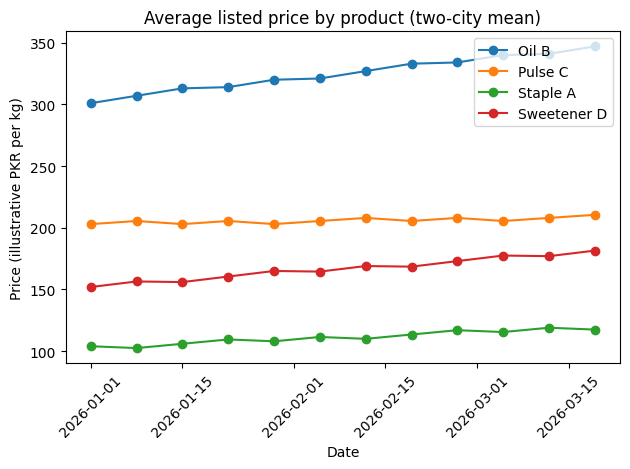

In [6]:
for item in item_weekly.item.unique():
    subset = item_weekly[item_weekly.item == item]
    plt.plot(subset.date, subset.price, marker="o", label=item)
plt.title("Average listed price by product (two-city mean)")
plt.xlabel("Date")
plt.ylabel("Price (illustrative PKR per kg)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Question 2 — Is City 2 higher than City 1 for every matched observation?

Pair each product and date across the two cities, then calculate City 2 minus City 1.

In [7]:
paired = df.pivot_table(index=["date", "item"], columns="city", values="price")
paired["difference_city2_minus_city1"] = paired["City 2"] - paired["City 1"]
print(paired.head(10))
print("Difference counts:", paired.difference_city2_minus_city1.value_counts().sort_index(), sep="\n")
print("All City 2 observations are higher:", bool((paired.difference_city2_minus_city1 > 0).all()))

city                    City 1  City 2  difference_city2_minus_city1
date       item                                                     
2026-01-01 Oil B         298.0   304.0                           6.0
           Pulse C       200.0   206.0                           6.0
           Staple A      101.0   107.0                           6.0
           Sweetener D   149.0   155.0                           6.0
2026-01-08 Oil B         304.0   310.0                           6.0
           Pulse C       202.5   208.5                           6.0
           Staple A       99.5   105.5                           6.0
           Sweetener D   153.5   159.5                           6.0
2026-01-15 Oil B         310.0   316.0                           6.0
           Pulse C       200.0   206.0                           6.0
Difference counts:
difference_city2_minus_city1
6.0    48
Name: count, dtype: int64
All City 2 observations are higher: True


In [8]:
city_summary = df.groupby("city").price.agg(["count", "mean", "min", "max"])
city_summary

,count,mean,min,max
city,,,,
City 1,48,199.166667,99.5,344.0
City 2,48,205.166667,105.5,350.0


## 5. Limits of what the data can establish

In [9]:
print("Rows:", len(df))
print("Products:", df.item.nunique())
print("Cities:", df.city.nunique())
print("Weeks:", df.date.nunique())
print("Income, wages or household budgets included?", False)
print("National/provincial coverage established?", False)
print("Data explicitly marked illustrative?", df.data_label.str.contains("ILLUSTRATIVE", case=False).all())

Rows: 96
Products: 4
Cities: 2
Weeks: 12
Income, wages or household budgets included? False
National/provincial coverage established? False
Data explicitly marked illustrative? True


## 6. Conclusion

In this teaching dataset, the two-city average price increased from the first to the last recorded week for all four listed products. City 2 was exactly PKR 6 per kg above City 1 for every matched product-date observation. These results describe only the supplied illustrative sample. They do not establish that everything in Pakistan became more expensive, that households cannot afford staples, or that the figures represent actual PBS market observations.